# Stage 7b - Conservation-vulnerability matrix

This notebook prepares **CFEV Integrated Conservation Values** (CFEV ICV) as a categorical 100 m raster aligned to **Intrinsic vulnerability (100m)**, then describes the observed cell combinations. The inputs are read-only during matrix construction. Category codes preserve the source classes; this stage does not assign combined priority classes.

Run the setup cell first, then 7b.1 before 7b.2. The 7b.1 rasterisation cell can verify and reuse an existing matching CFEV ICV raster. The existing raster and CSV filenames are retained.


In [1]:
# Stage 7b inputs and imports. Run this notebook from the project's `notebooks` directory.
from pathlib import Path
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

# Set AT3_DATA_DIR to the dataset root if it is not already configured.
data = Path(os.environ.get("AT3_DATA_DIR", "data"))
inpath = data / "Input_data"
outpath = data / "Output_data"


## 7b.1 CFEV Integrated Conservation Values (100 m)

Rasterise CFEV ICV polygons on the exact 100 m grid of **Intrinsic vulnerability (100m)** (`intrinsic_vulnerability_tas_100m_EPSG7855.tif`). This output is **CFEV Integrated Conservation Values** (`cfev_icv_tas_100m_EPSG7855.tif`). `KT_ICV` values are retained as categorical classes: `M` = Moderate, `H` = High, and `VH` = Very High. The raster uses category codes 1, 2 and 3 only as stored labels (not weights); 0 means unmatched within Intrinsic vulnerability (100m), and 255 is NoData outside Intrinsic vulnerability (100m)'s valid area. Intrinsic vulnerability (100m) itself is read only.

For each grid cell, calculate the exact intersection area with each class footprint. Same-class features are dissolved first. Where category polygons overlap geometrically, the higher category owns the overlapping area; if the remaining category areas in a cell tie, the higher category wins (Very High > High > Moderate). Two invalid source geometries are repaired with `make_valid()` before reprojection.

The check figure shows the CFEV polygons with Intrinsic vulnerability (100m)'s valid-cell boundary and the resulting categorical CFEV Integrated Conservation Values.


In [2]:
# Create CFEV Integrated Conservation Values on the exact Intrinsic vulnerability (100m) grid.
import math
import shapely
from shapely.ops import unary_union

RASTER_A_NAME = "Intrinsic vulnerability (100m)"
RASTER_B_NAME = "CFEV Integrated Conservation Values"
RASTER_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
CFEV_PATH = inpath / "LIST_CFEV_KARST_STATEWIDE" / "list_cfev_karst_statewide.shp"
RASTER_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"
CHECK_FIGURE_PATH = Path("..") / "figures" / "cfev_icv_raster_b_check.png"

if not RASTER_A_PATH.is_file():
    raise FileNotFoundError(f"{RASTER_A_NAME} is required and is not modified: {RASTER_A_PATH}")
if not CFEV_PATH.is_file():
    raise FileNotFoundError(f"CFEV ICV shapefile not found: {CFEV_PATH}")
if RASTER_B_PATH.resolve() == RASTER_A_PATH.resolve():
    raise ValueError("CFEV Integrated Conservation Values path must not overwrite Intrinsic vulnerability (100m)")

with rasterio.open(RASTER_A_PATH) as src_a:
    a_profile = src_a.profile.copy()
    a_transform = src_a.transform
    a_crs = src_a.crs
    a_shape = src_a.shape
    a_values = src_a.read(1, masked=False)
    a_valid = (src_a.dataset_mask() > 0) & np.isfinite(a_values)
    a_nodata = src_a.nodata

print(f"{RASTER_A_NAME} grid (target grid for {RASTER_B_NAME}):")
print(f"  CRS={a_crs}; shape={a_shape}; resolution={a_transform.a:g} x {-a_transform.e:g} m")
print(f"  transform={a_transform}; bounds={rasterio.transform.array_bounds(*a_shape, a_transform)}")
print(f"  NoData={a_nodata}; valid cells={int(a_valid.sum()):,}; NoData cells={a_valid.size - int(a_valid.sum()):,}")

cfev_source = gpd.read_file(CFEV_PATH)
source_crs = cfev_source.crs
source_bounds = cfev_source.total_bounds.copy()
source_invalid = ~cfev_source.geometry.is_valid
source_invalid_count = int(source_invalid.sum())
source_categories = cfev_source["KT_ICV"].value_counts(dropna=False).to_dict()
print("\nCFEV source metadata:")
print(f"  CRS={source_crs}; features={len(cfev_source):,}; extent={source_bounds}")
print(f"  geometry types={cfev_source.geom_type.value_counts().to_dict()}")
print(f"  invalid geometries before repair={source_invalid_count}; KT_ICV feature counts={source_categories}")

ICV_CODE = {"M": 1, "H": 2, "VH": 3}
ICV_LABEL = {1: "Moderate", 2: "High", 3: "Very High"}
ICV_COLOURS = {1: "#f4d35e", 2: "#ee964b", 3: "#c44536"}
unknown_categories = set(cfev_source["KT_ICV"].dropna().unique()) - set(ICV_CODE)
if unknown_categories or cfev_source["KT_ICV"].isna().any():
    raise ValueError(f"Unexpected or missing KT_ICV categories: {unknown_categories}")

cfev = cfev_source.to_crs(a_crs).copy()
cfev["geometry"] = cfev.geometry.make_valid()
if not cfev.geometry.is_valid.all():
    raise ValueError("One or more CFEV geometries remain invalid after make_valid()")

# Dissolve same-category features. Give geometric overlaps to the higher category
# before measuring cell areas, so overlapping source polygons are never double-counted.
raw_footprints = {code: unary_union(cfev.loc[cfev["KT_ICV"] == category, "geometry"].tolist())
                  for category, code in ICV_CODE.items()}
category_footprints = {}
occupied = None
for code in (3, 2, 1):  # explicit tie and overlap precedence: Very High > High > Moderate
    footprint = raw_footprints[code]
    category_footprints[code] = footprint if occupied is None else footprint.difference(occupied)
    occupied = footprint if occupied is None else unary_union([occupied, footprint])

# For every intersecting grid cell, measure polygon intersection area in square metres.
# Categories are processed highest-first; an area tie within 0.01 m2 keeps the higher category.
best_area = np.zeros(a_shape, dtype="float64")
winner = np.zeros(a_shape, dtype="uint8")
area_tie_tolerance_m2 = 0.01
for code in (3, 2, 1):
    footprint = category_footprints[code]
    components = list(footprint.geoms) if hasattr(footprint, "geoms") else [footprint]
    for component in components:
        if component.is_empty:
            continue
        x_min, y_min, x_max, y_max = component.bounds
        col0 = max(0, math.floor((x_min - a_transform.c) / a_transform.a))
        col1 = min(a_shape[1], math.ceil((x_max - a_transform.c) / a_transform.a))
        row0 = max(0, math.floor((a_transform.f - y_max) / -a_transform.e))
        row1 = min(a_shape[0], math.ceil((a_transform.f - y_min) / -a_transform.e))
        if row1 <= row0 or col1 <= col0:
            continue
        rows, cols = np.mgrid[row0:row1, col0:col1]
        rows, cols = rows.ravel(), cols.ravel()
        x_left = a_transform.c + cols * a_transform.a
        x_right = x_left + a_transform.a
        y_top = a_transform.f + rows * a_transform.e
        y_bottom = y_top + a_transform.e
        cell_boxes = shapely.box(x_left, y_bottom, x_right, y_top)
        area = shapely.area(shapely.intersection(cell_boxes, component))
        hit = area > 1e-8
        rows, cols, area = rows[hit], cols[hit], area[hit]
        replace = area > best_area[rows, cols] + area_tie_tolerance_m2
        rows, cols, area = rows[replace], cols[replace], area[replace]
        best_area[rows, cols] = area
        winner[rows, cols] = code

# Code 0 is unmatched within the intrinsic layer; code 255 is CFEV NoData.
raster_b = np.full(a_shape, 255, dtype="uint8")
raster_b[a_valid] = 0
covered = a_valid & (winner > 0)
raster_b[covered] = winner[covered]
valid_count = int(a_valid.sum())
category_counts = {code: int(((raster_b == code) & a_valid).sum()) for code in ICV_LABEL}
unmatched_count = int(((raster_b == 0) & a_valid).sum())
print(f"\nCFEV coverage within {RASTER_A_NAME} valid area:")
for code, label in ICV_LABEL.items():
    count = category_counts[code]
    print(f"  {label}: {count:,} cells ({100 * count / valid_count:.3f}%)")
print(f"  Unmatched: {unmatched_count:,} cells ({100 * unmatched_count / valid_count:.3f}%)")

b_profile = a_profile.copy()
b_profile.update(dtype="uint8", count=1, nodata=255, compress="deflate")
if RASTER_B_PATH.exists():
    # Reuse a matching product if OneDrive or a GIS application has the TIFF open.
    with rasterio.open(RASTER_B_PATH) as existing_b:
        same_grid = (existing_b.crs == a_crs and existing_b.transform == a_transform
                     and existing_b.shape == a_shape and existing_b.nodata == 255)
        same_values = same_grid and np.array_equal(existing_b.read(1), raster_b)
    if not same_values:
        raise FileExistsError(f"Existing {RASTER_B_NAME} differs from this run and will not be overwritten: {RASTER_B_PATH}")
    print(f"Existing {RASTER_B_NAME} matches this run; reuse it without overwriting.")
else:
    with rasterio.open(RASTER_B_PATH, "w", **b_profile) as dst_b:
        dst_b.write(raster_b, 1)
        dst_b.update_tags(
            CATEGORY_0="Unmatched within Intrinsic vulnerability valid area",
            CATEGORY_1="Moderate (source KT_ICV=M)",
            CATEGORY_2="High (source KT_ICV=H)",
            CATEGORY_3="Very High (source KT_ICV=VH)",
            NODATA_255="Outside Intrinsic vulnerability valid area",
            OVERLAP_RULE="Cell category with greatest intersection area; ties to higher category: Very High > High > Moderate",
            GEOMETRY_REPAIR=f"shapely.make_valid applied to {source_invalid_count} invalid source geometries",
        )
print(f"\nCFEV Integrated Conservation Values saved: {RASTER_B_PATH}")
# Discard overlay working arrays before drawing the statewide diagnostic figure.
del best_area, winner, a_values

# Visual check: render a lightweight statewide preview in the project's projected-map style.
# The CFEV raster remains full-resolution; only the PNG preview is downsampled for compact rendering.
from PIL import Image, ImageDraw, ImageFont, ImageFilter

map_bounds = rasterio.transform.array_bounds(*a_shape, a_transform)
xmin, ymin, xmax, ymax = map_bounds
map_w, map_h = 650, 820  # matches the 100 m grid's statewide aspect ratio
canvas = Image.new("RGB", (1510, 1040), "white")
draw = ImageDraw.Draw(canvas)
font = ImageFont.load_default()
draw.text((755, 24), "Tasmania CFEV Integrated Conservation Values (100 m)",
          fill="#202a35", font=font, anchor="mm")
left_xy, right_xy = (70, 145), (790, 145)
for xy, title in ((left_xy, "CFEV ICV polygons + Intrinsic vulnerability valid boundary"),
                  (right_xy, "CFEV Integrated Conservation Values: largest category area per cell")):
    draw.text((xy[0] + map_w // 2, 112), title, fill="#202a35", font=font, anchor="mm")

def map_xy(x, y, origin):
    px = origin[0] + (x - xmin) / (xmax - xmin) * map_w
    py = origin[1] + (ymax - y) / (ymax - ymin) * map_h
    return (int(round(px)), int(round(py)))

left_map = Image.new("RGB", (map_w, map_h), "#e9eef2")
left_draw = ImageDraw.Draw(left_map)
for category, code in (("M", 1), ("H", 2), ("VH", 3)):
    color = ICV_COLOURS[code]
    for geom in cfev.loc[cfev["KT_ICV"] == category, "geometry"]:
        parts = list(geom.geoms) if hasattr(geom, "geoms") else [geom]
        for polygon in parts:
            coords = [map_xy(x, y, (0, 0)) for x, y in polygon.exterior.coords]
            if len(coords) >= 3:
                left_draw.polygon(coords, fill=color)
# Overlay the valid area boundary from Intrinsic vulnerability's actual mask. A 10-cell preview
# (1 km) is used for this visual outline only; the conservation raster remains at exact 100 m.
preview_step = 10
mask_preview = Image.fromarray((a_valid[::preview_step, ::preview_step].astype("uint8") * 255), mode="L")
mask_preview = mask_preview.resize((map_w, map_h), resample=Image.Resampling.NEAREST)
edge = mask_preview.filter(ImageFilter.FIND_EDGES).point(lambda value: 255 if value > 40 else 0)
left_map.paste("#111111", mask=edge)
canvas.paste(left_map, left_xy)

# Render the categorical output at 1 km display resolution; unmatched cells are grey,
# while NoData outside the intrinsic layer remains transparent over the light background.
b_preview = raster_b[::preview_step, ::preview_step]
b_rgb = np.empty((*b_preview.shape, 3), dtype="uint8")
b_rgb[:] = (233, 238, 242)
for code, color in ((0, "#8c8c8c"), (1, ICV_COLOURS[1]), (2, ICV_COLOURS[2]), (3, ICV_COLOURS[3])):
    rgb = tuple(int(color.lstrip("#")[i:i + 2], 16) for i in (0, 2, 4))
    b_rgb[b_preview == code] = rgb
right_map = Image.fromarray(b_rgb, mode="RGB").resize((map_w, map_h), resample=Image.Resampling.NEAREST)
canvas.paste(right_map, right_xy)
draw = ImageDraw.Draw(canvas)

# Coordinate grid and map furniture, matching the rest of Stage 7's projected maps.
for origin in (left_xy, right_xy):
    ox, oy = origin
    for i in range(1, 4):
        xx = ox + map_w * i // 4
        yy = oy + map_h * i // 4
        draw.line((xx, oy, xx, oy + map_h), fill="#ffffff", width=1)
        draw.line((ox, yy, ox + map_w, yy), fill="#ffffff", width=1)
    draw.rectangle((ox, oy, ox + map_w - 1, oy + map_h - 1), outline="#53616d", width=2)
    draw.text((ox + map_w - 28, oy + 18), "N", fill="#111111", font=font, anchor="mm")
    draw.line((ox + map_w - 28, oy + 42, ox + map_w - 28, oy + 23), fill="#111111", width=3)
    bar_px = round(50000 / (xmax - xmin) * map_w)
    bx, by = ox + 26, oy + map_h - 24
    draw.rectangle((bx, by, bx + bar_px, by + 5), fill="#111111")
    draw.text((bx, by - 13), "50 km", fill="#111111", font=font)

# Compact legends below both panels.
legend_y = 985
draw.text((left_xy[0], legend_y), "CFEV:   M Moderate     H High     VH Very High   |   black outline: Intrinsic vulnerability valid area",
          fill="#202a35", font=font)
draw.text((right_xy[0], legend_y), "CFEV Integrated Conservation Values:   grey unmatched     Moderate     High     Very High",
          fill="#202a35", font=font)
canvas.save(CHECK_FIGURE_PATH, format="PNG", optimize=True)
print(f"Visual check saved: {CHECK_FIGURE_PATH.resolve()}")


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1151077661.py:25: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a_values = src_a.read(1, masked=False)


Intrinsic vulnerability (100m) grid (target grid for CFEV Integrated Conservation Values):
  CRS=EPSG:7855; shape=(5020, 3987); resolution=100 x 100 m
  transform=| 100.00, 0.00, 227075.39|
| 0.00,-100.00, 5661951.49|
| 0.00, 0.00, 1.00|; bounds=(227075.3862292826, 5159951.486531957, 625775.3862292826, 5661951.486531957)
  NoData=-9999.0; valid cells=410,008; NoData cells=19,604,732

CFEV source metadata:
  CRS=EPSG:28355; features=334; extent=[ 229369.0935 5171940.3479  613643.0227 5614522.3767]
  geometry types={'Polygon': 206, 'MultiPolygon': 128}
  invalid geometries before repair=2; KT_ICV feature counts={'M': 186, 'H': 128, 'VH': 20}

CFEV coverage within Intrinsic vulnerability (100m) valid area:
  Moderate: 110,155 cells (26.867%)
  High: 189,388 cells (46.191%)
  Very High: 109,839 cells (26.789%)
  Unmatched: 626 cells (0.153%)
Existing CFEV Integrated Conservation Values matches this run; reuse it without overwriting.

CFEV Integrated Conservation Values saved: C:\Users\inno

C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1151077661.py:122: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  same_values = same_grid and np.array_equal(existing_b.read(1), raster_b)


## 7b.2 Intrinsic vulnerability by CFEV conservation-value matrix

Read Intrinsic vulnerability (100m) and CFEV Integrated Conservation Values in read-only mode and count every observed vulnerability-score by CFEV-category combination. Exclude Intrinsic vulnerability (100m) NoData and CFEV Integrated Conservation Values codes 0 (unmatched) and 255 (NoData). Percentages are reported both as a share of all eligible cells and within each intrinsic-vulnerability-score row. The output is a descriptive cross-tabulation only; it does not assign priority classes.


In [3]:
# Descriptive Intrinsic vulnerability (100m) x CFEV Integrated Conservation Values matrix; inputs are read only.
from PIL import Image, ImageDraw, ImageFont

MATRIX_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
MATRIX_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"
LONG_TABLE_PATH = outpath / "vulnerability_x_cfev_icv_cell_counts_tas_100m_EPSG7855.csv"
COUNT_MATRIX_PATH = outpath / "vulnerability_x_cfev_icv_count_matrix_tas_100m_EPSG7855.csv"
MATRIX_FIGURE_PATH = Path("..") / "figures" / "vulnerability_cfev_icv_matrix_tas_100m_EPSG7855.png"

with rasterio.open(MATRIX_A_PATH, "r") as src_a, rasterio.open(MATRIX_B_PATH, "r") as src_b:
    if not (src_a.crs == src_b.crs and src_a.transform == src_b.transform and src_a.shape == src_b.shape):
        raise ValueError(f"{RASTER_A_NAME} and {RASTER_B_NAME} do not share an identical grid")
    score = src_a.read(1)
    a_valid = (src_a.dataset_mask() > 0) & np.isfinite(score)
    icv = src_b.read(1)
    b_nodata = src_b.nodata

allowed_codes = {0, 1, 2, 3, 255}
found_codes = set(np.unique(icv).tolist())
if not found_codes.issubset(allowed_codes):
    raise ValueError(f"Unexpected {RASTER_B_NAME} category codes: {found_codes - allowed_codes}")
# Explicit exclusions: intrinsic-layer NoData; conservation codes 0 (unmatched) and 255 (NoData).
eligible = a_valid & (icv != 0) & (icv != 255)
if b_nodata is not None:
    eligible &= icv != b_nodata
if not eligible.any():
    raise ValueError("No matched intrinsic-vulnerability/CFEV cells remain for the cross-tabulation")

# Intrinsic vulnerability stores float32 scores rounded to six decimals; normalize display/group keys.
score_key = np.round(score[eligible].astype("float64"), 6)
category_code = icv[eligible].astype("uint8")
category_labels = {1: "Moderate", 2: "High", 3: "Very High"}
counts = pd.crosstab(
    pd.Series(score_key, name="vulnerability_score"),
    pd.Series(category_code, name="icv_code"),
).reindex(columns=[1, 2, 3], fill_value=0).sort_index()
counts.columns = [category_labels[c] for c in counts.columns]
counts.index.name = "vulnerability_score"
eligible_count = int(eligible.sum())

records = []
for score_value, row in counts.iterrows():
    score_total = int(row.sum())
    for label in category_labels.values():
        cell_count = int(row[label])
        records.append({
            "vulnerability_score": float(score_value),
            "cfev_icv_category": label,
            "cell_count": cell_count,
            "percent_of_eligible_cells": 100 * cell_count / eligible_count,
            "percent_within_vulnerability_score": 100 * cell_count / score_total if score_total else 0.0,
        })
long_table = pd.DataFrame.from_records(records)
counts.to_csv(COUNT_MATRIX_PATH, index=True, float_format="%.6f")
long_table.to_csv(LONG_TABLE_PATH, index=False, float_format="%.6f")

print(f"Eligible matched cells: {eligible_count:,}")
print(f"Excluded: {RASTER_A_NAME} NoData={int((~a_valid).sum()):,}; {RASTER_B_NAME} unmatched=0: {int((a_valid & (icv == 0)).sum()):,}; {RASTER_B_NAME} NoData=255: {int((a_valid & (icv == 255)).sum()):,}")
print("\nCell counts and percentages (all observed score x category combinations):")
print(long_table.to_string(index=False, formatters={
    "percent_of_eligible_cells": "{:.3f}%".format,
    "percent_within_vulnerability_score": "{:.2f}%".format,
}))
print("\nCount matrix:")
print(counts.to_string())
top_combinations = long_table.sort_values("cell_count", ascending=False).head(10)
print("\nTen most common combinations:")
print(top_combinations.to_string(index=False, formatters={
    "percent_of_eligible_cells": "{:.3f}%".format,
    "percent_within_vulnerability_score": "{:.2f}%".format,
}))

# Render a compact count heatmap. Cell fill uses log-scaled counts for legibility;
# printed labels are the untransformed cell counts. This is not a priority score.
try:
    title_font = ImageFont.truetype("arial.ttf", 22)
    header_font = ImageFont.truetype("arial.ttf", 17)
    body_font = ImageFont.truetype("arial.ttf", 16)
except OSError:
    title_font = header_font = body_font = ImageFont.load_default()
row_h, cell_w, left_w = 42, 220, 190
img_w = left_w + 3 * cell_w + 40
img_h = 120 + len(counts) * row_h + 36
heat = Image.new("RGB", (img_w, img_h), "white")
draw = ImageDraw.Draw(heat)
draw.text((img_w // 2, 20), "Intrinsic vulnerability x CFEV Integrated Conservation Values (cell counts)",
          fill="#202a35", font=title_font, anchor="ma")
draw.text((left_w + (3 * cell_w) // 2, 70), f"Eligible cells: {eligible_count:,}",
          fill="#40515f", font=header_font, anchor="mm")
for j, label in enumerate(counts.columns):
    x0 = left_w + j * cell_w
    draw.text((x0 + cell_w // 2, 102), label, fill="#202a35", font=header_font, anchor="mm")
max_count = int(counts.to_numpy().max())
log_max = np.log1p(max_count)
for i, (score_value, row) in enumerate(counts.iterrows()):
    y0 = 120 + i * row_h
    draw.text((left_w - 12, y0 + row_h // 2), f"{score_value:.6f}",
              fill="#202a35", font=body_font, anchor="rm")
    for j, label in enumerate(counts.columns):
        value = int(row[label])
        fraction = np.log1p(value) / log_max if log_max else 0.0
        # Pale blue for low counts, dark navy for the most frequent cells.
        blue = int(245 - 150 * fraction)
        fill = (blue, min(250, blue + 8), 255)
        x0 = left_w + j * cell_w
        draw.rectangle((x0, y0, x0 + cell_w - 2, y0 + row_h - 2), fill=fill, outline="white")
        text_color = "white" if fraction > 0.68 else "#202a35"
        draw.text((x0 + cell_w // 2, y0 + row_h // 2), f"{value:,}",
                  fill=text_color, font=body_font, anchor="mm")
heat.save(MATRIX_FIGURE_PATH, format="PNG", optimize=True)
print(f"\nSaved detailed table: {LONG_TABLE_PATH}")
print(f"Saved count matrix: {COUNT_MATRIX_PATH}")
print(f"Saved heatmap: {MATRIX_FIGURE_PATH.resolve()}")


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\2985974189.py:13: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  score = src_a.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\2985974189.py:15: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  icv = src_b.read(1)


Eligible matched cells: 409,382
Excluded: Intrinsic vulnerability (100m) NoData=19,604,732; CFEV Integrated Conservation Values unmatched=0: 626; CFEV Integrated Conservation Values NoData=255: 0

Cell counts and percentages (all observed score x category combinations):
 vulnerability_score cfev_icv_category  cell_count percent_of_eligible_cells percent_within_vulnerability_score
            0.041667          Moderate           0                    0.000%                              0.00%
            0.041667              High          31                    0.008%                            100.00%
            0.041667         Very High           0                    0.000%                              0.00%
            0.062500          Moderate          69                    0.017%                              4.04%
            0.062500              High          61                    0.015%                              3.57%
            0.062500         Very High        1579       

## 7b.3 Provisional three-group vulnerability ? CFEV table

Group the original **Intrinsic vulnerability (100m)** scores as Lower (0.041667 to 0.1875), Middle (0.25 to 0.375), and Higher (0.5 to 1.0), then cross-tabulate against Moderate, High, and Very High CFEV ICV. These group boundaries are provisional. Counts and percentages are recalculated from the two rasters; percentages use eligible cells (valid Raster A and CFEV codes 1 to 3) as the denominator.

In [4]:
# Provisional three-group table calculated directly from the two read-only rasters.
from IPython.display import display

GROUP_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
GROUP_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"

with rasterio.open(GROUP_A_PATH, "r") as src_a, rasterio.open(GROUP_B_PATH, "r") as src_b:
    if not (src_a.crs == src_b.crs and src_a.transform == src_b.transform and src_a.shape == src_b.shape):
        raise ValueError(f"{RASTER_A_NAME} and {RASTER_B_NAME} do not share an identical grid")
    scores = src_a.read(1)
    a_valid = (src_a.dataset_mask() > 0) & np.isfinite(scores)
    icv = src_b.read(1)
    b_nodata = src_b.nodata

eligible = a_valid & (icv != 0) & (icv != 255)
if b_nodata is not None:
    eligible &= icv != b_nodata
if not eligible.any():
    raise ValueError("No eligible matched cells remain")

# Match the published six-decimal vulnerability score values when applying bands.
score_values = np.round(scores.astype("float64"), 6)
low = eligible & (score_values >= 0.041667) & (score_values <= 0.1875)
mid = eligible & (score_values >= 0.25) & (score_values <= 0.375)
high = eligible & (score_values >= 0.5) & (score_values <= 1.0)
assigned = low | mid | high
if not np.array_equal(assigned, eligible):
    unexpected = np.unique(score_values[eligible & ~assigned])
    raise ValueError(f"Eligible scores fall outside the proposed groups: {unexpected.tolist()}")
if not set(np.unique(icv[eligible]).tolist()).issubset({1, 2, 3}):
    raise ValueError("Eligible CFEV cells contain codes outside 1 (Moderate), 2 (High), and 3 (Very High)")

group_code = np.zeros(scores.shape, dtype="uint8")
group_code[low] = 1
group_code[mid] = 2
group_code[high] = 3
group_names = {1: "Lower", 2: "Middle", 3: "Higher"}
icv_names = {1: "Moderate", 2: "High", 3: "Very High"}
priority_names = {
    (1, 1): "Lower priority", (1, 2): "Conservation interest", (1, 3): "High conservation significance",
    (2, 1): "Vulnerability concern", (2, 2): "High priority", (2, 3): "Very high priority",
    (3, 1): "Vulnerability concern", (3, 2): "Very high priority", (3, 3): "Highest priority",
}
cell_counts = pd.crosstab(
    pd.Series(group_code[eligible], name="Vulnerability group"),
    pd.Series(icv[eligible], name="CFEV category"),
).reindex(index=[1, 2, 3], columns=[1, 2, 3], fill_value=0)
cell_counts.index = [group_names[i] for i in cell_counts.index]
cell_counts.columns = [icv_names[i] for i in cell_counts.columns]
eligible_count = int(eligible.sum())

result = cell_counts.copy().astype(object)
for row_code, row_name in group_names.items():
    for col_code, col_name in icv_names.items():
        count = int(cell_counts.loc[row_name, col_name])
        percent = 100 * count / eligible_count
        result.loc[row_name, col_name] = f"{count:,} ({percent:.2f}%) | {priority_names[(row_code, col_code)]}"

# Ensure the grouped table accounts for every eligible cell before displaying it.
assert int(cell_counts.to_numpy().sum()) == eligible_count
print(f"Eligible cells: {eligible_count:,}; grouped table total: {int(cell_counts.to_numpy().sum()):,}")
display(result)


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\2981685594.py:10: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  scores = src_a.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\2981685594.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  icv = src_b.read(1)


Eligible cells: 409,382; grouped table total: 409,382


,Moderate,High,Very High
Lower,"20,472 (5.00%) | Lower priority","63,796 (15.58%) | Conservation interest","5,076 (1.24%) | High conservation significance"
Middle,"59,797 (14.61%) | Vulnerability concern","98,868 (24.15%) | High priority","52,408 (12.80%) | Very high priority"
Higher,"29,886 (7.30%) | Vulnerability concern","26,724 (6.53%) | Very high priority","52,355 (12.79%) | Highest priority"


## 7b.4 Provisional conservation-vulnerability priority classes

Assign a provisional priority class to each eligible cell using the score groups above and the CFEV ICV category. The rules are: Priority 1 (Highest) = Higher + Very High; Priority 2 (High) = Higher + High or Middle + Very High; Priority 3 (Moderate) = Middle + Moderate/High, Higher + Moderate, or Lower + Very High; Priority 4 (Lower) = Lower + Moderate/High. These priority classes are provisional. Intrinsic vulnerability (100m) NoData and CFEV Integrated Conservation Values codes 0 (unmatched) and 255 (NoData) remain unassigned as NoData in the output.

In [5]:
# Assign provisional priority codes from the two existing rasters; inputs are read only.
PRIORITY_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
PRIORITY_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"
PRIORITY_RASTER_PATH = outpath / "vulnerability_conservation_priority_tas_100m_EPSG7855.tif"
PRIORITY_NODATA = 255
PRIORITY_LABELS = {1: "Priority 1 - Highest", 2: "Priority 2 - High", 3: "Priority 3 - Moderate", 4: "Priority 4 - Lower"}

with rasterio.open(PRIORITY_A_PATH, "r") as src_a, rasterio.open(PRIORITY_B_PATH, "r") as src_b:
    if not (src_a.crs == src_b.crs and src_a.transform == src_b.transform and src_a.shape == src_b.shape):
        raise ValueError(f"{RASTER_A_NAME} and {RASTER_B_NAME} do not share an identical grid")
    priority_profile = src_a.profile.copy()
    priority_scores = src_a.read(1)
    priority_a_valid = (src_a.dataset_mask() > 0) & np.isfinite(priority_scores)
    priority_icv = src_b.read(1)
    priority_b_nodata = src_b.nodata

priority_icv_codes = set(np.unique(priority_icv).tolist())
if not priority_icv_codes.issubset({0, 1, 2, 3, 255}):
    raise ValueError(f"Unexpected {RASTER_B_NAME} category codes: {priority_icv_codes - {0, 1, 2, 3, 255}}")
priority_eligible = priority_a_valid & (priority_icv != 0) & (priority_icv != 255)
if priority_b_nodata is not None:
    priority_eligible &= priority_icv != priority_b_nodata

priority_score_values = np.round(priority_scores.astype("float64"), 6)
priority_lower_group = (priority_score_values >= 0.041667) & (priority_score_values <= 0.1875)
priority_middle_group = (priority_score_values >= 0.25) & (priority_score_values <= 0.375)
priority_higher_group = (priority_score_values >= 0.5) & (priority_score_values <= 1.0)
priority_output = np.full(priority_scores.shape, PRIORITY_NODATA, dtype="uint8")

# Rules: 1 = Higher/VH; 2 = Higher/H or Middle/VH; 3 = Middle/M-H, Higher/M, Lower/VH;
# 4 = Lower/M-H. Raster B codes: 1 = Moderate, 2 = High, 3 = Very High.
priority_rules = {
    1: priority_eligible & priority_higher_group & (priority_icv == 3),
    2: priority_eligible & ((priority_higher_group & (priority_icv == 2)) |
                            (priority_middle_group & (priority_icv == 3))),
    3: priority_eligible & ((priority_middle_group & np.isin(priority_icv, [1, 2])) |
                            (priority_higher_group & (priority_icv == 1)) |
                            (priority_lower_group & (priority_icv == 3))),
    4: priority_eligible & priority_lower_group & np.isin(priority_icv, [1, 2]),
}
for priority_code, rule_mask in priority_rules.items():
    priority_output[rule_mask] = priority_code

assigned_priority = priority_output != PRIORITY_NODATA
if not np.array_equal(assigned_priority, priority_eligible):
    uncovered = int((priority_eligible & ~assigned_priority).sum())
    unexpected_scores = np.unique(priority_score_values[priority_eligible & ~assigned_priority])
    raise ValueError(f"{uncovered:,} eligible cells were not assigned; unexpected scores: {unexpected_scores.tolist()}")
if int(assigned_priority.sum()) != int(priority_eligible.sum()):
    raise AssertionError("Priority cell counts do not reconcile with eligible cells")

priority_profile.update(dtype="uint8", count=1, nodata=PRIORITY_NODATA, compress="deflate")
if PRIORITY_RASTER_PATH.exists():
    with rasterio.open(PRIORITY_RASTER_PATH, "r") as existing_priority:
        same_grid = (existing_priority.crs == priority_profile["crs"] and
                     existing_priority.transform == priority_profile["transform"] and
                     existing_priority.shape == (priority_profile["height"], priority_profile["width"]))
        same_values = same_grid and existing_priority.nodata == PRIORITY_NODATA and np.array_equal(
            existing_priority.read(1), priority_output
        )
    if not same_values:
        raise FileExistsError(f"Existing priority raster differs from the calculated result and was preserved: {PRIORITY_RASTER_PATH}")
    print(f"Preserved existing matching priority raster: {PRIORITY_RASTER_PATH}")
else:
    with rasterio.open(PRIORITY_RASTER_PATH, "w", **priority_profile) as dst:
        dst.write(priority_output, 1)
    print(f"Created priority raster: {PRIORITY_RASTER_PATH}")

priority_counts = {code: int((priority_output == code).sum()) for code in PRIORITY_LABELS}
print(f"Provisional priority raster: {PRIORITY_RASTER_PATH}")
print(f"Eligible cells assigned: {sum(priority_counts.values()):,} / {int(priority_eligible.sum()):,}")
print(f"Unassigned cells (NoData): {int((~assigned_priority).sum()):,}")
print("Priority class counts and percentages of eligible cells:")
for code, label in PRIORITY_LABELS.items():
    count = priority_counts[code]
    print(f"  {label}: {count:,} ({100 * count / int(priority_eligible.sum()):.2f}%)")


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1224875455.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  priority_scores = src_a.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1224875455.py:14: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  priority_icv = src_b.read(1)


Provisional priority raster: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\vulnerability_conservation_priority_tas_100m_EPSG7855.tif
Eligible cells assigned: 409,382 / 409,382
Unassigned cells (NoData): 19,605,358
Priority class counts and percentages of eligible cells:
  Priority 1 - Highest: 52,355 (12.79%)
  Priority 2 - High: 79,132 (19.33%)
  Priority 3 - Moderate: 193,627 (47.30%)
  Priority 4 - Lower: 84,268 (20.58%)


## 7b.5 Statewide area statistics by priority

Calculate priority cell counts and areas from the saved priority raster and the actual Raster A cell dimensions. Percentages use the matched eligible footprint (valid Intrinsic vulnerability (100m) cells with CFEV Integrated Conservation Values codes 1-3). This summarizes the provisional priority classes.

In [6]:
# Statewide priority counts and area statistics from the actual Raster A grid.
from IPython.display import display

STATS_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
STATS_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"
STATS_PRIORITY_PATH = outpath / "vulnerability_conservation_priority_tas_100m_EPSG7855.tif"

with rasterio.open(STATS_A_PATH, "r") as src_a, rasterio.open(STATS_B_PATH, "r") as src_b, rasterio.open(STATS_PRIORITY_PATH, "r") as src_priority:
    if not (src_a.crs == src_b.crs == src_priority.crs and
            src_a.transform == src_b.transform == src_priority.transform and
            src_a.shape == src_b.shape == src_priority.shape):
        raise ValueError("Raster A, Raster B, and the priority raster must share an identical grid")
    if src_a.crs is None or not src_a.crs.is_projected:
        raise ValueError("A projected CRS is required to calculate area in square kilometres")
    stats_transform = src_a.transform
    stats_scores = src_a.read(1)
    stats_a_valid = (src_a.dataset_mask() > 0) & np.isfinite(stats_scores)
    stats_icv = src_b.read(1)
    stats_b_nodata = src_b.nodata
    stats_priority = src_priority.read(1)
    stats_priority_nodata = src_priority.nodata

stats_eligible = stats_a_valid & (stats_icv != 0) & (stats_icv != 255)
if stats_b_nodata is not None:
    stats_eligible &= stats_icv != stats_b_nodata
stats_priority_valid = (stats_priority != stats_priority_nodata) & (stats_priority != 255)
if not np.array_equal(stats_priority_valid, stats_eligible):
    raise AssertionError("Priority raster valid cells do not match the eligible Raster A/B cells")
if not set(np.unique(stats_priority[stats_priority_valid]).tolist()).issubset({1, 2, 3, 4}):
    raise ValueError("Priority raster contains an unexpected priority code")

# Affine determinant gives true cell area, including any rotation or shear, in CRS units squared.
cell_area_m2 = abs(stats_transform.a * stats_transform.e - stats_transform.b * stats_transform.d)
if cell_area_m2 <= 0:
    raise ValueError(f"Invalid raster cell area from transform: {stats_transform}")
cell_area_km2 = cell_area_m2 / 1_000_000
eligible_cells = int(stats_eligible.sum())
eligible_area_km2 = eligible_cells * cell_area_km2
stats_priority_labels = {1: "Priority 1 - Highest", 2: "Priority 2 - High", 3: "Priority 3 - Moderate", 4: "Priority 4 - Lower"}
priority_stats_rows = []
for code, label in stats_priority_labels.items():
    count = int((stats_priority == code).sum())
    area_km2 = count * cell_area_km2
    priority_stats_rows.append({
        "Priority category": label,
        "Cells": count,
        "Area (km^2)": area_km2,
        "Percent of eligible cells": 100 * count / eligible_cells,
        "Percent of eligible karst area": 100 * area_km2 / eligible_area_km2,
    })
priority_area_stats = pd.DataFrame(priority_stats_rows)

count_total = int(priority_area_stats["Cells"].sum())
area_total_km2 = float(priority_area_stats["Area (km^2)"].sum())
cell_percent_total = float(priority_area_stats["Percent of eligible cells"].sum())
area_percent_total = float(priority_area_stats["Percent of eligible karst area"].sum())
if count_total != eligible_cells:
    raise AssertionError(f"Priority counts ({count_total:,}) do not reconcile with eligible cells ({eligible_cells:,})")
if not np.isclose(area_total_km2, eligible_area_km2, rtol=0, atol=1e-9):
    raise AssertionError(f"Priority areas ({area_total_km2:.9f} km^2) do not reconcile with eligible area ({eligible_area_km2:.9f} km^2)")
if not np.isclose(cell_percent_total, 100.0, rtol=0, atol=1e-9):
    raise AssertionError(f"Cell percentages sum to {cell_percent_total:.12f}%, not 100%")
if not np.isclose(area_percent_total, 100.0, rtol=0, atol=1e-9):
    raise AssertionError(f"Area percentages sum to {area_percent_total:.12f}%, not 100%")

print(f"Raster cell dimensions: {abs(stats_transform.a):g} m x {abs(stats_transform.e):g} m; cell area: {cell_area_m2:,.2f} m^2 ({cell_area_km2:.8f} km^2)")
print(f"Eligible total: {eligible_cells:,} cells; {eligible_area_km2:,.4f} km^2")
display(priority_area_stats.style.format({
    "Cells": "{:,.0f}",
    "Area (km^2)": "{:,.4f}",
    "Percent of eligible cells": "{:.2f}%",
    "Percent of eligible karst area": "{:.2f}%",
}))
print(f"Reconciliation: {count_total:,} cells; {area_total_km2:,.4f} km^2; {cell_percent_total:.2f}% of cells; {area_percent_total:.2f}% of eligible area")


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1373638148.py:16: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  stats_scores = src_a.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1373638148.py:18: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  stats_icv = src_b.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1373638148.py:20: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  stats_priority = src_priority.read(1)


Raster cell dimensions: 100 m x 100 m; cell area: 10,000.00 m^2 (0.01000000 km^2)
Eligible total: 409,382 cells; 4,093.8200 km^2


,Priority category,Cells,Area (km^2),Percent of eligible cells,Percent of eligible karst area
0,Priority 1 - Highest,"52,355",523.5500,12.79%,12.79%
1,Priority 2 - High,"79,132",791.3200,19.33%,19.33%
2,Priority 3 - Moderate,"193,627","1,936.2700",47.30%,47.30%
3,Priority 4 - Lower,"84,268",842.6800,20.58%,20.58%


Reconciliation: 409,382 cells; 4,093.8200 km^2; 100.00% of cells; 100.00% of eligible area


## 7b.6 Fractional priority summaries for original Karst Atlas polygons

Use the original `karst_tas_EPSG7855.gpkg` features as assessment units. As in `07_statewide_application` and `src/karst.py`, derive `karst_intensity` from `KCATEGORY` and retain features where `karst_intensity > 0`; do not dissolve or split features. `OBJECTID` identifies each feature and `KNAME` supplies its name where present.

For each polygon, intersect its geometry with eligible 100 m grid cells and attribute the exact polygon-cell intersection area to that cell's priority, original vulnerability score, and CFEV category. This is equivalent to allocating each cell's area by its intersected fraction. Invalid geometry is repaired only on an in-memory copy for overlay. Overlapping Atlas polygons are summarized independently, so their summaries can overlap. Statewide totals are calculated separately from unique eligible raster cells and are not summed from polygon rows. Polygon rows use fractional boundary-cell areas, while statewide area counts full eligible cells; polygon-area sums therefore need not equal the statewide raster footprint. A tie in dominant area is assigned to the highest priority (Priority 1). Cells with Raster A NoData or Raster B code 0/255 are excluded and receive no priority.

Limitations: the source scores and priority classes are still 100 m raster classifications, so fractional weighting improves boundary accounting but does not add finer thematic detail. Unmatched and NoData cells are omitted. Blank `KNAME` values remain blank. The output reports polygons with no intersecting eligible area with zero eligible area and no dominant priority. An invalid source geometry is temporarily repaired for the intersection calculation; no source geometries are written back.

In [7]:
# Fractional cell-area summaries by original Karst Atlas polygon; statewide totals are cell-based.
import json as json_module
import sys
import shapely
from IPython.display import display

# Ensure the shared frozen karst method is importable whether Jupyter starts in the project root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import importlib.util
_KARST_MODULE_SPEC = importlib.util.spec_from_file_location("project_karst", PROJECT_ROOT / "src" / "karst.py")
if _KARST_MODULE_SPEC is None or _KARST_MODULE_SPEC.loader is None:
    raise ImportError(f"Could not load shared karst methods from {PROJECT_ROOT / 'src' / 'karst.py'}")
_KARST_MODULE = importlib.util.module_from_spec(_KARST_MODULE_SPEC)
_KARST_MODULE_SPEC.loader.exec_module(_KARST_MODULE)
add_karst_susceptibility = _KARST_MODULE.add_karst_susceptibility

ATLAS_POLYGONS_PATH = outpath / "karst_tas_EPSG7855.gpkg"
PRIORITY_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
PRIORITY_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"
PRIORITY_RASTER_PATH = outpath / "vulnerability_conservation_priority_tas_100m_EPSG7855.tif"
POLYGON_PRIORITY_SUMMARY_PATH = outpath / "karst_polygon_priority_summary_tas_100m_EPSG7855.csv"
STATEWIDE_PRIORITY_SUMMARY_PATH = outpath / "priority_statewide_area_summary_tas_100m_EPSG7855.csv"
POLYGON_PRIORITY_LABELS = {1: "Priority 1 - Highest", 2: "Priority 2 - High", 3: "Priority 3 - Moderate", 4: "Priority 4 - Lower"}
POLYGON_ICV_LABELS = {1: "Moderate", 2: "High", 3: "Very High"}

with rasterio.open(PRIORITY_A_PATH, "r") as src_a, rasterio.open(PRIORITY_B_PATH, "r") as src_b, rasterio.open(PRIORITY_RASTER_PATH, "r") as src_priority:
    if not (src_a.crs == src_b.crs == src_priority.crs and
            src_a.transform == src_b.transform == src_priority.transform and
            src_a.shape == src_b.shape == src_priority.shape):
        raise ValueError("Raster A, Raster B, and priority raster must share an identical grid")
    if src_a.crs is None or not src_a.crs.is_projected:
        raise ValueError("A projected CRS is required for area-weighted polygon summaries")
    atlas_transform = src_a.transform
    atlas_crs = src_a.crs
    raster_height, raster_width = src_a.shape
    atlas_scores = src_a.read(1)
    atlas_a_valid = (src_a.dataset_mask() > 0) & np.isfinite(atlas_scores)
    atlas_icv = src_b.read(1)
    atlas_b_nodata = src_b.nodata
    atlas_priority = src_priority.read(1)
    atlas_priority_nodata = src_priority.nodata

# EPSG:7855 grid is north-up; this lets us form exact cell polygons from the affine transform.
if not np.isclose(atlas_transform.b, 0) or not np.isclose(atlas_transform.d, 0):
    raise ValueError("This fractional overlay cell-polygon construction expects the project's north-up raster grid")
cell_area_m2 = abs(atlas_transform.a * atlas_transform.e)
if not np.isclose(cell_area_m2, 10_000.0):
    raise ValueError(f"Expected 100 m raster cells (10,000 m^2), found {cell_area_m2:g} m^2")

atlas_eligible = atlas_a_valid & (atlas_icv != 0) & (atlas_icv != 255)
if atlas_b_nodata is not None:
    atlas_eligible &= atlas_icv != atlas_b_nodata
if atlas_priority_nodata is not None:
    atlas_eligible &= atlas_priority != atlas_priority_nodata
atlas_eligible &= atlas_priority != 255
if not set(np.unique(atlas_priority[atlas_eligible]).tolist()).issubset({1, 2, 3, 4}):
    raise ValueError("Eligible cells contain an unexpected priority code")
if not np.array_equal(atlas_eligible, (atlas_priority >= 1) & (atlas_priority <= 4)):
    raise AssertionError("Priority raster valid cells do not match eligible Raster A/B cells")

# Apply the same shared method and intensity > 0 selection used in Stage 7.
atlas_polygons_all = gpd.read_file(ATLAS_POLYGONS_PATH)
if atlas_polygons_all.crs != atlas_crs:
    raise ValueError(f"Atlas polygons CRS {atlas_polygons_all.crs} does not match raster CRS {atlas_crs}")
add_karst_susceptibility(atlas_polygons_all)
source_feature_count = len(atlas_polygons_all)
source_invalid_count = int((~atlas_polygons_all.geometry.is_valid).sum())
karst_polygons = atlas_polygons_all.loc[atlas_polygons_all["karst_intensity"] > 0].copy()
karst_polygon_count = len(karst_polygons)
invalid_karst_count = int((~karst_polygons.geometry.is_valid).sum())

polygon_rows = []
for _, feature in karst_polygons.iterrows():
    objectid = feature["OBJECTID"]
    name = feature.get("KNAME")
    geometry = feature.geometry
    if geometry is None or geometry.is_empty:
        geometry_area = np.zeros(4, dtype="float64")
        score_area = {}
        icv_area = {}
    else:
        if not geometry.is_valid:
            geometry = shapely.make_valid(geometry)  # repair the working copy only
        minx, miny, maxx, maxy = geometry.bounds
        # Raster A is north-up with positive x resolution and negative y resolution.
        # Compute the enclosing pixel window directly; rasterio.windows.from_bounds
        # crashes in the local rasterio/GDAL environment.
        row_start = max(0, int(np.floor((maxy - atlas_transform.f) / atlas_transform.e)))
        col_start = max(0, int(np.floor((minx - atlas_transform.c) / atlas_transform.a)))
        row_stop = min(raster_height, int(np.ceil((miny - atlas_transform.f) / atlas_transform.e)))
        col_stop = min(raster_width, int(np.ceil((maxx - atlas_transform.c) / atlas_transform.a)))
        priority_cell_areas = np.zeros(4, dtype="float64")
        score_area = {}
        icv_area = {label: 0.0 for label in POLYGON_ICV_LABELS.values()}
        if row_start < row_stop and col_start < col_stop:
            # Process small windows so a large Atlas polygon never creates cell geometries for its whole bounding box at once.
            tile_size = 128
            for tile_row_start in range(row_start, row_stop, tile_size):
                tile_row_stop = min(row_stop, tile_row_start + tile_size)
                for tile_col_start in range(col_start, col_stop, tile_size):
                    tile_col_stop = min(col_stop, tile_col_start + tile_size)
                    tile_eligible = atlas_eligible[tile_row_start:tile_row_stop, tile_col_start:tile_col_stop]
                    local_rows, local_cols = np.nonzero(tile_eligible)
                    if not len(local_rows):
                        continue
                    global_rows = local_rows + tile_row_start
                    global_cols = local_cols + tile_col_start
                    cell_x0 = atlas_transform.c + global_cols * atlas_transform.a
                    cell_x1 = cell_x0 + atlas_transform.a
                    cell_y0 = atlas_transform.f + global_rows * atlas_transform.e
                    cell_y1 = cell_y0 + atlas_transform.e
                    cell_geometries = shapely.box(np.minimum(cell_x0, cell_x1), np.minimum(cell_y0, cell_y1),
                                                  np.maximum(cell_x0, cell_x1), np.maximum(cell_y0, cell_y1))
                    intersection_areas = shapely.area(shapely.intersection(cell_geometries, geometry))
                    positive = intersection_areas > 0
                    if not positive.any():
                        continue
                    intersection_areas = intersection_areas[positive]
                    global_rows = global_rows[positive]
                    global_cols = global_cols[positive]
                    cell_priorities = atlas_priority[global_rows, global_cols]
                    cell_scores = np.round(atlas_scores[global_rows, global_cols].astype("float64"), 6)
                    cell_icv = atlas_icv[global_rows, global_cols]
                    for priority_code in range(1, 5):
                        priority_cell_areas[priority_code - 1] += float(intersection_areas[cell_priorities == priority_code].sum())
                    unique_scores, score_inverse = np.unique(cell_scores, return_inverse=True)
                    for score_value, area_m2 in zip(unique_scores, np.bincount(score_inverse, weights=intersection_areas)):
                        score_key = f"{score_value:.6f}"
                        score_area[score_key] = score_area.get(score_key, 0.0) + float(area_m2) / 1_000_000
                    for icv_code, icv_label in POLYGON_ICV_LABELS.items():
                        icv_area[icv_label] += float(intersection_areas[cell_icv == icv_code].sum()) / 1_000_000
        geometry_area = priority_cell_areas

    eligible_area_m2 = float(geometry_area.sum())
    eligible_area_km2 = eligible_area_m2 / 1_000_000
    record = {
        "OBJECTID": int(objectid),
        "KNAME": None if pd.isna(name) else str(name),
        "eligible_area_km2": eligible_area_km2,
    }
    for priority_code, label in POLYGON_PRIORITY_LABELS.items():
        area_km2 = float(geometry_area[priority_code - 1]) / 1_000_000
        record[f"{label} area_km2"] = area_km2
        record[f"{label} percent"] = 100 * area_km2 / eligible_area_km2 if eligible_area_km2 else np.nan
    priority12_area_km2 = float(geometry_area[:2].sum()) / 1_000_000
    record["Priority 1+2 area_km2"] = priority12_area_km2
    record["Priority 1+2 percent"] = 100 * priority12_area_km2 / eligible_area_km2 if eligible_area_km2 else np.nan
    dominant_codes = np.flatnonzero(np.isclose(geometry_area, geometry_area.max(), rtol=0, atol=1e-8)) + 1 if eligible_area_m2 else []
    record["dominant_priority"] = POLYGON_PRIORITY_LABELS[int(dominant_codes[0])] if len(dominant_codes) else "No eligible cells"
    record["dominant_priority_percent"] = 100 * float(geometry_area[int(dominant_codes[0]) - 1]) / eligible_area_m2 if len(dominant_codes) and eligible_area_m2 else np.nan
    record["vulnerability_score_distribution_area_km2_pct"] = json_module.dumps({
        key: {"area_km2": round(value, 8), "percent": round(100 * value / eligible_area_km2, 6) if eligible_area_km2 else None}
        for key, value in score_area.items()
    }, separators=(",", ":"), sort_keys=True)
    record["cfev_category_distribution_area_km2_pct"] = json_module.dumps({
        key: {"area_km2": round(value, 8), "percent": round(100 * value / eligible_area_km2, 6) if eligible_area_km2 else None}
        for key, value in icv_area.items()
    }, separators=(",", ":"), sort_keys=True)
    polygon_rows.append(record)

polygon_priority_summary = pd.DataFrame(polygon_rows).sort_values("OBJECTID").reset_index(drop=True)

# Statewide totals use each eligible raster cell once, independently of polygon overlap.
statewide_eligible_count = int(atlas_eligible.sum())
statewide_eligible_area_km2 = statewide_eligible_count * cell_area_m2 / 1_000_000
statewide_rows = []
for priority_code, label in POLYGON_PRIORITY_LABELS.items():
    count = int((atlas_priority[atlas_eligible] == priority_code).sum())
    area_km2 = count * cell_area_m2 / 1_000_000
    statewide_rows.append({
        "Priority category": label,
        "Cells": count,
        "Area_km2": area_km2,
        "Percent of eligible cells": 100 * count / statewide_eligible_count,
        "Percent of eligible karst area": 100 * area_km2 / statewide_eligible_area_km2,
    })
statewide_priority_summary = pd.DataFrame(statewide_rows)

if not np.allclose(polygon_priority_summary[[f"{label} area_km2" for label in POLYGON_PRIORITY_LABELS.values()]].sum(axis=1),
                   polygon_priority_summary["eligible_area_km2"], rtol=0, atol=1e-8):
    raise AssertionError("One or more polygon priority areas do not sum to that polygon's eligible area")
if int(statewide_priority_summary["Cells"].sum()) != statewide_eligible_count:
    raise AssertionError("Statewide priority counts do not reconcile with eligible raster cells")
if not np.isclose(statewide_priority_summary["Area_km2"].sum(), statewide_eligible_area_km2, rtol=0, atol=1e-9):
    raise AssertionError("Statewide priority areas do not reconcile with eligible raster area")

def save_csv_preserving_existing(frame, output_path):
    csv_text = frame.to_csv(index=False, float_format="%.12f")
    if output_path.exists():
        existing_text = output_path.read_text(encoding="utf-8-sig")
        if existing_text != csv_text:
            raise FileExistsError(f"Existing CSV differs from the calculated result and was preserved: {output_path}")
        print(f"Preserved existing matching CSV: {output_path}")
    else:
        with output_path.open("w", encoding="utf-8-sig", newline="") as output_file:
            output_file.write(csv_text)
        print(f"Created CSV: {output_path}")

save_csv_preserving_existing(polygon_priority_summary, POLYGON_PRIORITY_SUMMARY_PATH)
save_csv_preserving_existing(statewide_priority_summary, STATEWIDE_PRIORITY_SUMMARY_PATH)
print(f"Karst Atlas source features: {source_feature_count:,}; selected with karst_intensity > 0: {karst_polygon_count:,}")
print(f"Invalid source geometries: {source_invalid_count:,}; invalid selected karst geometries repaired on temporary copies: {invalid_karst_count:,}")
print(f"Polygon summary CSV: {POLYGON_PRIORITY_SUMMARY_PATH}")
print(f"Statewide summary CSV: {STATEWIDE_PRIORITY_SUMMARY_PATH}")
print(f"Polygon rows: {len(polygon_priority_summary):,}; polygons with no eligible raster overlap: {int((polygon_priority_summary['eligible_area_km2'] == 0).sum()):,}")
print("Polygon summary preview (full results are in the CSV):")
display(polygon_priority_summary.head(10))
print(f"Statewide eligible footprint (counted once): {statewide_eligible_count:,} cells; {statewide_eligible_area_km2:,.4f} km^2")
print("Statewide priority totals:")
display(statewide_priority_summary.style.format({
    "Cells": "{:,.0f}", "Area_km2": "{:,.4f}",
    "Percent of eligible cells": "{:.2f}%", "Percent of eligible karst area": "{:.2f}%",
}))
print("Polygon summaries are independent; overlapping source polygons may count the same raster area in more than one polygon row.")


C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1046935607.py:38: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  atlas_scores = src_a.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1046935607.py:40: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  atlas_icv = src_b.read(1)
C:\Users\innoc\AppData\Local\Temp\ipykernel_24660\1046935607.py:42: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  atlas_priority = src_priority.read(1)


Karst Atlas source features: 2,601; selected with karst_intensity > 0: 1,677
Invalid source geometries: 8; invalid selected karst geometries repaired on temporary copies: 1
Polygon summary CSV: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\karst_polygon_priority_summary_tas_100m_EPSG7855.csv
Statewide summary CSV: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\priority_statewide_area_summary_tas_100m_EPSG7855.csv
Polygon rows: 1,677; polygons with no eligible raster overlap: 43
Polygon summary preview (full results are in the CSV):


,OBJECTID,KNAME,eligible_area_km2,Priority 1 - Highest area_km2,Priority 1 - Highest percent,Priority 2 - High area_km2,Priority 2 - High percent,Priority 3 - Moderate area_km2,Priority 3 - Moderate percent,Priority 4 - Lower area_km2,Priority 4 - Lower percent,Priority 1+2 area_km2,Priority 1+2 percent,dominant_priority,dominant_priority_percent,vulnerability_score_distribution_area_km2_pct,cfev_category_distribution_area_km2_pct
0,296,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
1,298,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
2,299,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
3,301,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
4,303,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
5,304,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
6,457,Martha Lavinia,1.596942,0.0,0.0,0.000000,0.0,1.596942,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.375000"":{""area_km2"":1.59694211,""percent"":1...","{""High"":{""area_km2"":0.0,""percent"":0.0},""Modera..."
7,458,Martha Lavinia,2.418431,0.0,0.0,0.000000,0.0,2.418431,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.375000"":{""area_km2"":2.41843115,""percent"":1...","{""High"":{""area_km2"":0.0,""percent"":0.0},""Modera..."
8,460,Fraser River,25.484940,0.0,0.0,0.000000,0.0,25.484940,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.250000"":{""area_km2"":25.4849398,""percent"":1...","{""High"":{""area_km2"":25.4849398,""percent"":100.0..."
9,461,Blowhole,0.048489,0.0,0.0,0.048489,100.0,0.000000,0.0,0.0,0.0,0.048489,100.0,Priority 2 - High,100.0,"{""0.562500"":{""area_km2"":0.04848942,""percent"":1...","{""High"":{""area_km2"":0.04848942,""percent"":100.0..."


Statewide eligible footprint (counted once): 409,382 cells; 4,093.8200 km^2
Statewide priority totals:


,Priority category,Cells,Area_km2,Percent of eligible cells,Percent of eligible karst area
0,Priority 1 - Highest,"52,355",523.5500,12.79%,12.79%
1,Priority 2 - High,"79,132",791.3200,19.33%,19.33%
2,Priority 3 - Moderate,"193,627","1,936.2700",47.30%,47.30%
3,Priority 4 - Lower,"84,268",842.6800,20.58%,20.58%


Polygon summaries are independent; overlapping source polygons may count the same raster area in more than one polygon row.


Overlap check for effect gave this result: There are two positive-area overlaps, involving four polygons. Their total overlap footprint is 0.010433 km² (about 10,433 m², or 1.04 100 m cell areas). That is 0.000254% of the selected polygons’ combined area, so the statewide effect is negligible.
The overlap does touch eligible priority cells: 0.009852 km² across seven cells, about 0.000241% of the statewide eligible area. However, all four affected polygons—OBJECTID 2598–2601, each named Lower Black River - South Forest—have 100% of their eligible area within those overlaps. Their polygon-level summaries will therefore duplicate that small area completely.
Assessment: the overlaps are negligible statewide, but material for those four individual polygon records. The geometry check repaired one invalid selected polygon in memory; the source layer was left unchanged.

## 7b.7 Priority outputs, tables, and statewide map

Validate and reuse the classified priority raster and saved statewide and polygon CSV summaries. Existing outputs are preserved: matching files are reused, and a conflicting existing file causes an error instead of being overwritten. Display the summary tables, then create the statewide **Karst Conservation Priority Map** using the project's projected-coordinate map style, basemap, coordinate grid, scale bar, north arrow, attribution, and a four-class priority legend.

C:\Users\innoc\AppData\Local\Temp\ipykernel_12132\2846944695.py:38: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  b = src_b.read(1, window=win)
C:\Users\innoc\AppData\Local\Temp\ipykernel_12132\2846944695.py:39: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  priority = src_priority.read(1, window=win)
C:\Users\innoc\AppData\Local\Temp\ipykernel_12132\2846944695.py:47: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  priority_preview = src_priority.read(1, out_shape=(preview_height, preview_width),


Statewide priority table: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\priority_statewide_area_summary_tas_100m_EPSG7855.csv


,Priority category,Cells,Area_km2,Percent of eligible cells,Percent of eligible karst area
0,Priority 1 - Highest,"52,355",523.5500,12.79%,12.79%
1,Priority 2 - High,"79,132",791.3200,19.33%,19.33%
2,Priority 3 - Moderate,"193,627","1,936.2700",47.30%,47.30%
3,Priority 4 - Lower,"84,268",842.6800,20.58%,20.58%


Polygon summary table: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\karst_polygon_priority_summary_tas_100m_EPSG7855.csv (1,677 original polygons). Showing a preview; the CSV contains all rows and distributions.


,OBJECTID,KNAME,eligible_area_km2,Priority 1 - Highest area_km2,Priority 1 - Highest percent,Priority 2 - High area_km2,Priority 2 - High percent,Priority 3 - Moderate area_km2,Priority 3 - Moderate percent,Priority 4 - Lower area_km2,Priority 4 - Lower percent,Priority 1+2 area_km2,Priority 1+2 percent,dominant_priority,dominant_priority_percent,vulnerability_score_distribution_area_km2_pct,cfev_category_distribution_area_km2_pct
0,296,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
1,298,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
2,299,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
3,301,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
4,303,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
5,304,Monument,0.000000,0.0,NaN,0.000000,NaN,0.000000,NaN,0.0,NaN,0.000000,NaN,No eligible cells,NaN,{},"{""High"":{""area_km2"":0.0,""percent"":null},""Moder..."
6,457,Martha Lavinia,1.596942,0.0,0.0,0.000000,0.0,1.596942,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.375000"":{""area_km2"":1.59694211,""percent"":1...","{""High"":{""area_km2"":0.0,""percent"":0.0},""Modera..."
7,458,Martha Lavinia,2.418431,0.0,0.0,0.000000,0.0,2.418431,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.375000"":{""area_km2"":2.41843115,""percent"":1...","{""High"":{""area_km2"":0.0,""percent"":0.0},""Modera..."
8,460,Fraser River,25.484940,0.0,0.0,0.000000,0.0,25.484940,100.0,0.0,0.0,0.000000,0.0,Priority 3 - Moderate,100.0,"{""0.250000"":{""area_km2"":25.4849398,""percent"":1...","{""High"":{""area_km2"":25.4849398,""percent"":100.0..."
9,461,Blowhole,0.048489,0.0,0.0,0.048489,100.0,0.000000,0.0,0.0,0.0,0.048489,100.0,Priority 2 - High,100.0,"{""0.562500"":{""area_km2"":0.04848942,""percent"":1...","{""High"":{""area_km2"":0.04848942,""percent"":100.0..."


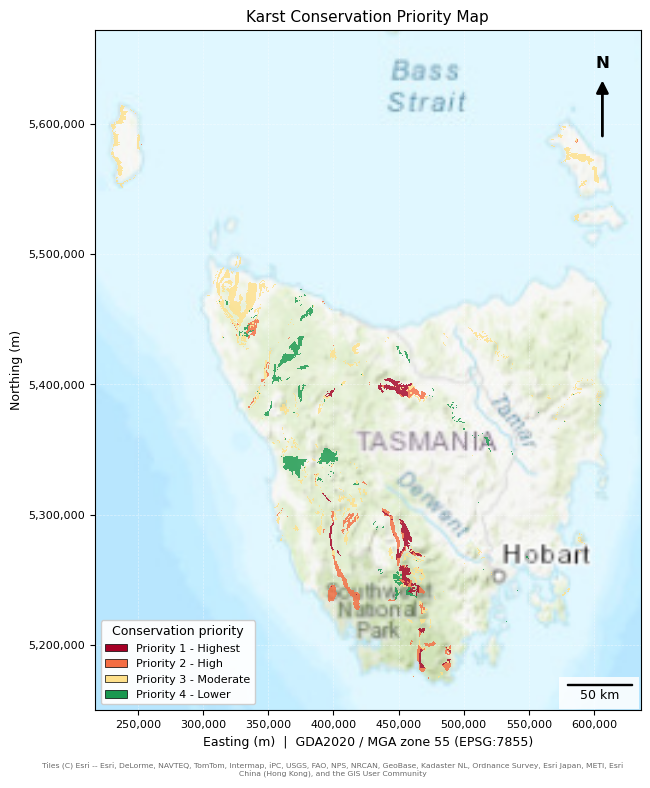

Created map: c:\Users\innoc\Documents\Uni\KGG375\AT3\AT3_Group3_2026\figures\karst_conservation_priority_map_tas_100m_EPSG7855_with_basemap.png
Classified priority raster verified on the exact Raster A grid: C:\Users\innoc\OneDrive - University of Tasmania\AT3_initial_datasets\Output_data\vulnerability_conservation_priority_tas_100m_EPSG7855.tif


In [4]:
# Validate existing outputs, display both saved summary tables, and create the statewide priority map.
from IPython.display import Image as NotebookImage, display
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import sys
import importlib.util

OUTPUT_PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
OUTPUT_PRIORITY_PATH = outpath / "vulnerability_conservation_priority_tas_100m_EPSG7855.tif"
OUTPUT_STATEWIDE_CSV = outpath / "priority_statewide_area_summary_tas_100m_EPSG7855.csv"
OUTPUT_POLYGON_CSV = outpath / "karst_polygon_priority_summary_tas_100m_EPSG7855.csv"
OUTPUT_MAP_PATH = OUTPUT_PROJECT_ROOT / "figures" / "karst_conservation_priority_map_tas_100m_EPSG7855_with_basemap.png"
OUTPUT_A_PATH = outpath / "intrinsic_vulnerability_tas_100m_EPSG7855.tif"
OUTPUT_B_PATH = outpath / "cfev_icv_tas_100m_EPSG7855.tif"

required_outputs = [OUTPUT_PRIORITY_PATH, OUTPUT_STATEWIDE_CSV, OUTPUT_POLYGON_CSV]
missing_outputs = [path for path in required_outputs if not path.is_file()]
if missing_outputs:
    raise FileNotFoundError(f"Run the priority and summary cells first; missing outputs: {missing_outputs}")

# Validate in manageable windows and build a display-sized overview to limit peak memory.
with rasterio.open(OUTPUT_A_PATH, "r") as src_a, rasterio.open(OUTPUT_B_PATH, "r") as src_b, rasterio.open(OUTPUT_PRIORITY_PATH, "r") as src_priority:
    if not (src_a.crs == src_b.crs == src_priority.crs and
            src_a.transform == src_b.transform == src_priority.transform and
            src_a.shape == src_b.shape == src_priority.shape):
        raise ValueError("The priority raster is not aligned exactly with Raster A and Raster B")
    priority_map_nodata = src_priority.nodata
    priority_map_transform = src_priority.transform
    priority_map_crs = src_priority.crs
    if priority_map_nodata != 255:
        raise ValueError(f"Expected priority-raster NoData=255, found {priority_map_nodata}")
    for row_off in range(0, src_a.height, 512):
        for col_off in range(0, src_a.width, 512):
            win = rasterio.windows.Window(col_off, row_off,
                min(512, src_a.width-col_off), min(512, src_a.height-row_off))
            a = src_a.read(1, window=win, masked=True)
            b = src_b.read(1, window=win)
            priority = src_priority.read(1, window=win)
            eligible = (~np.ma.getmaskarray(a) & np.isfinite(a.data) & (b != 0) & (b != 255))
            if src_b.nodata is not None:
                eligible &= b != src_b.nodata
            if not np.array_equal(eligible, (priority >= 1) & (priority <= 4)):
                raise AssertionError(f"Priority raster footprint mismatch in window {win}")
    preview_height = min(src_priority.height, 800)
    preview_width = min(src_priority.width, 800)
    priority_preview = src_priority.read(1, out_shape=(preview_height, preview_width),
        resampling=rasterio.enums.Resampling.nearest)
    priority_map_values = priority_preview

statewide_summary_table = pd.read_csv(OUTPUT_STATEWIDE_CSV)
polygon_summary_table = pd.read_csv(OUTPUT_POLYGON_CSV)
if len(polygon_summary_table) != 1677 or polygon_summary_table["OBJECTID"].nunique() != len(polygon_summary_table):
    raise AssertionError("Polygon summary CSV does not contain one unique row for each selected Atlas polygon")
print(f"Statewide priority table: {OUTPUT_STATEWIDE_CSV}")
display(statewide_summary_table.style.format({
    "Cells": "{:,.0f}", "Area_km2": "{:,.4f}",
    "Percent of eligible cells": "{:.2f}%", "Percent of eligible karst area": "{:.2f}%",
}))
print(f"Polygon summary table: {OUTPUT_POLYGON_CSV} ({len(polygon_summary_table):,} original polygons). Showing a preview; the CSV contains all rows and distributions.")
display(polygon_summary_table.head(10))

if OUTPUT_MAP_PATH.exists():
    print(f"Preserving existing map and displaying it: {OUTPUT_MAP_PATH}")
    display(NotebookImage(filename=str(OUTPUT_MAP_PATH)))
else:
    map_spec = importlib.util.spec_from_file_location("project_mapping", OUTPUT_PROJECT_ROOT / "src" / "mapping.py")
    if map_spec is None or map_spec.loader is None:
        raise ImportError(f"Could not load project map helpers from {OUTPUT_PROJECT_ROOT / 'src' / 'mapping.py'}")
    project_mapping = importlib.util.module_from_spec(map_spec)
    map_spec.loader.exec_module(project_mapping)

    priority_labels = {
        1: "Priority 1 - Highest",
        2: "Priority 2 - High",
        3: "Priority 3 - Moderate",
        4: "Priority 4 - Lower",
    }
    priority_colours = {1: "#a50026", 2: "#f46d43", 3: "#fee08b", 4: "#1a9850"}
    map_cmap = ListedColormap([priority_colours[k] for k in range(1, 5)])
    map_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], map_cmap.N)
    map_masked = np.ma.masked_where((priority_map_values < 1) | (priority_map_values > 4), priority_map_values)
    left, right, bottom, top = project_mapping.raster_extent(priority_map_transform, (src_priority.height, src_priority.width))
    fig, ax = plt.subplots(figsize=(7, 8))
    basemap_ok = False
    try:
        project_mapping.add_basemap(ax, (left, bottom, right, top), margin=10000,
                                    crs=priority_map_crs, zoom=6)
        basemap_ok = True
    except Exception as exc:
        ax.set_xlim(left - 10000, right + 10000)
        ax.set_ylim(bottom - 10000, top + 10000)
        ax.set_facecolor("#f2f2f2")
        print(f"Basemap tiles unavailable; using the project coordinate-map layout without tiles: {exc}")
    ax.imshow(map_masked, cmap=map_cmap, norm=map_norm, alpha=0.82,
              extent=(left, right, bottom, top), interpolation="nearest", zorder=2)
    legend_handles = [Patch(facecolor=priority_colours[k], edgecolor="black", linewidth=0.5,
                            label=priority_labels[k]) for k in range(1, 5)]
    ax.legend(handles=legend_handles, title="Conservation priority", loc="lower left",
              fontsize=8, title_fontsize=9, framealpha=0.95)
    ax.set_title("Karst Conservation Priority Map", fontsize=11)
    project_mapping.style_map_axes(ax)
    project_mapping.add_scalebar(ax, 50000, "50 km")
    project_mapping.add_north_arrow(ax)
    if basemap_ok:
        project_mapping.add_attribution(ax)
    fig.subplots_adjust(left=0.12, right=0.98, bottom=0.09, top=0.94)
    OUTPUT_MAP_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_MAP_PATH, dpi=120)
    plt.show()
    plt.close(fig)
    print(f"Created map: {OUTPUT_MAP_PATH}")

print(f"Classified priority raster verified on the exact Raster A grid: {OUTPUT_PRIORITY_PATH}")
